<a href="https://colab.research.google.com/github/solasobambo-prog/ts-data-science/blob/main/week4c.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tuesday Python Class Summary Notes (Week 2)


## 1. Variables
* **Purpose:** Variables act as named containers that store data values in memory for reuse later in a program.
* **Example from class:** `value_1 = 10` and `value_2 = 5` store integer numbers, while `name`, `lastname`, and `firstname` store text strings.

---

## 2. Arithmetic Operators
Python uses standard symbols to perform math calculations on stored numbers:
* **Addition (`+`):** Adds two values together (`10 + 5` gives `15`).
* **Subtraction (`-`):** Subtracts the second value from the first (`10 - 5` gives `5`).
* **Multiplication (`*`):** Multiplies two values (`10 * 5` gives `50`).
* **Standard Division (`/`):** Divides two numbers and always returns a decimal/float (`10 / 5` gives `2.0`).
* **Floor Division (`//`):** Divides two numbers and rounds down toward negative infinity to return an integer (`10 // 3` gives `3`, while `-7 // 2` gives `-4`, not `-3`).

---

## 3. Division Guard (`if` Statement)
* **Purpose:** Dividing by zero crashes a Python program with a `ZeroDivisionError`.
* **How it works:** Using `if value_2 != 0:` checks that the divisor is not equal to zero before calculating. If it is zero, the `else` block safely catches it and prints an error message instead.

```python
if value_2 != 0:
    division_result = value_1 / value_2
else:
    print("Error: Division by zero is not allowed.")
```

---

## 4. User Input & Cleaning (`.strip()`)
* **Reading Input (`input()`):** Pauses the program and waits for the user to type something, always saving the answer as a string.
* **Removing Extra Spaces (`.strip()`):** Chaining `.strip()` onto `input()` removes any accidental leading or trailing spaces the user might type.

```python
name = input("What is your name? ").strip()
```

---

## 5. Formatted Strings (F-Strings)
* **Purpose:** F-strings (`f"..."`) make it easy to embed variables and expressions directly inside text using curly braces `{}`.
* **Fallback Values:** Writing `{name or 'friend'}` displays the user's name if they entered one, or defaults to `'friend'` if they left it blank. Because an empty string (`""`) evaluates as `False` in Python, the `or` operator falls back to returning the second value (`'friend'`).

```python
print(f"Hello, {name or 'friend'}!")
```

---

## 6. String Formatting Methods
* **`.upper()`:** Converts every character in a string to ALL CAPS (e.g., `"oko"` becomes `"OKO"`).
* **`.title()`:** Capitalizes the first letter of each word in a string and makes the rest lowercase (e.g., `"adebayo"` becomes `"Adebayo"`).

```python
print(f"Hello, {lastname.upper()}!")
print(f"Hello, {firstname.title()}!")
```

---

## 7. One Thing Still Unclear
* **Floor Division Zero Guard:** The class script protects standard division (`/`) with `if value_2 != 0:`, but leaves floor division (`//`) outside that check. Since `value_1 // 0` also raises a `ZeroDivisionError`, the `if` guard should cover both division operations.


## Chart Choice Table

In [3]:
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

def load_csv(slug):
    path = kagglehub.dataset_download(slug)
    csv_files = [f for f in os.listdir(path) if f.endswith('.csv')]
    if not csv_files:
        raise FileNotFoundError(f"No CSV file found in {path}")
    return pd.read_csv(os.path.join(path, csv_files[0]))

telco = load_csv("blastchar/telco-customer-churn")
telco['TotalCharges'] = pd.to_numeric(telco['TotalCharges'], errors='coerce')
print(f"TotalCharges coerced to NaN (blank strings): {telco['TotalCharges'].isna().sum()}")
telco['churn_flag'] = (telco['Churn'] == 'Yes').astype(int)

airbnb = load_csv("dgomonov/new-york-city-airbnb-open-data")

telco_raw = telco.copy()
airbnb_raw = airbnb.copy()

def finish(ax, title, xlabel, ylabel):
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    sns.despine(ax=ax)

print(f"Loaded Telco (n={len(telco):,}) and Airbnb (n={len(airbnb):,})")

TotalCharges coerced to NaN (blank strings): 11
Loaded Telco (n=7,043) and Airbnb (n=48,895)


### Part 2: Chart Choice Table (Pre-Plot Commitment)

| # | Question | Question Type | Chart to Use | Chart to Avoid (with Reason) |
| :--- | :--- | :--- | :--- | :--- |
| **1** | **Telco:** Which payment method has the highest churn rate? | **Comparison** (rates across categories) | **Horizontal sorted bar chart** (mean of `churn_flag` by `PaymentMethod`) | **Pie chart** — slices show shares of a whole rather than independent risk rates, and long payment labels overlap easily. |
| **2** | **Telco:** What share of customers is on each contract type? | **Composition** (part-to-whole) | **Sorted vertical bar chart** (with percentage labels) | **Pie chart** — human eyes judge bar lengths along a common baseline far more accurately than angles and slice areas. |
| **3** | **Airbnb:** What does a typical listing price look like? | **Distribution** (single numeric variable) | **Histogram** (with median/IQR lines, clipped or zoomed below the extreme right tail) | **Bar chart of individual prices** — continuous numeric values would create hundreds of unreadable bars without grouping into bins. |
| **4** | **Airbnb:** Does price differ across neighbourhood groups? | **Group Comparison** (distribution across categories) | **Horizontal boxplot** (sorted by median, with `showfliers=False` or upper-fence clip) | **Bar chart of mean prices** — extreme luxury listings ($10,000/night) inflate the mean and hide the spread and skewness within each borough. |
| **5** | **Telco:** Does total spend rise with tenure? | **Relationship** (two numeric variables, split by group) | **Faceted scatter plot** (`sns.relplot` with `col='Contract'`) | **Line plot** — connecting individual customer IDs in arbitrary order creates noisy zig-zags rather than showing a clean bivariate trend. |
| **6 (Bonus)** | **Airbnb:** How does review activity move over time? | **Trend** (change over time) | **Line chart** (monthly count of `last_review` dates) | **Bar chart with dozens of monthly bars** — dense vertical bars clutter the time axis and obscure continuous momentum. |


#### Post-Plot Result Notes (Verified After Running Part 3)
* **Question 1 (Payment Method Churn):** Confirmed — `Electronic check` has the highest churn rate at **45.29%**, which is **3.0 times** the rate of `Credit card (automatic)` (**15.24%**).
* **Question 4 (Borough Price Comparison):** Confirmed (`n = 48,895`, outliers hidden via `showfliers=False`) — Manhattan has the highest median nightly price at **$150.00** (IQR **$125.00**), which is **2.3 times** the median of the Bronx (**$65.00**).
* **Question 5 (Tenure vs. Total Charges by Contract):** Confirmed (`n = 7,032` valid rows) — `TotalCharges` rises with `tenure` across every contract tier (`r = 0.93` for Month-to-month, `r = 0.80` for One year, `r = 0.63` for Two year), while the vertical spread fans out as tenure grows and Two-year contracts cluster at the 72-month cap (**20.4%** at 72 months).


=== PART 3: BUILD AND TEST CHOICES (QUESTIONS 1 & 4) ===


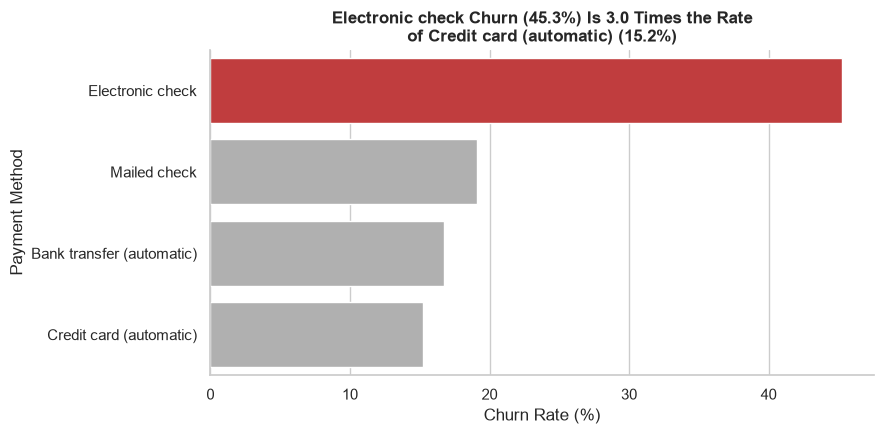

Q1 Churn Rates (%):
PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: churn_flag, dtype: float64


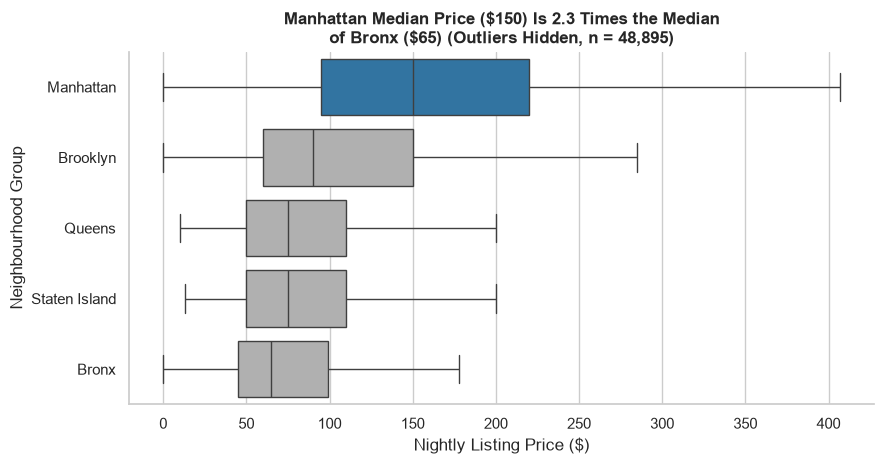


Q4 Borough Price Medians & IQRs:
                         n  median    iqr
neighbourhood_group                      
Manhattan            21661   150.0  125.0
Brooklyn             20104    90.0   90.0
Queens                5666    75.0   60.0
Staten Island          373    75.0   60.0
Bronx                 1091    65.0   54.0


In [4]:
print("=== PART 3: BUILD AND TEST CHOICES (QUESTIONS 1 & 4) ===")

# ---------------------------------------------------------------------
# QUESTION 1: Telco — Which payment method has the highest churn rate?
# ---------------------------------------------------------------------
# Prediction (Q1): Electronic check will have the highest churn rate (likely >40%), while automatic bank transfer and credit card methods will sit much lower (~15%–20%) due to frictionless auto-pay.

pay_rates = (telco.groupby('PaymentMethod')['churn_flag'].mean() * 100).sort_values(ascending=False)
pay_order = pay_rates.index.tolist()
top_pay = pay_order[0]
top_pay_rate = pay_rates.iloc[0]
low_pay = pay_order[-1]
low_pay_rate = pay_rates.iloc[-1]
pay_ratio = top_pay_rate / low_pay_rate

pay_palette = {m: ('#d62728' if m == top_pay else '#b0b0b0') for m in pay_order}

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(
    x=pay_rates.values, y=pay_rates.index, order=pay_order,
    palette=pay_palette, hue=pay_rates.index, legend=False, ax=ax
)
finish(
    ax,
    f'{top_pay} Churn ({top_pay_rate:.1f}%) Is {pay_ratio:.1f} Times the Rate\nof {low_pay} ({low_pay_rate:.1f}%)',
    'Churn Rate (%)',
    'Payment Method'
)
fig.tight_layout()
plt.show()

print("Q1 Churn Rates (%):")
print(pay_rates.round(2))
# Result check (Q1): Predicted Electronic check highest (>40%) and auto-pay lowest (15%-20%); actual Electronic check is 45.29% vs. Credit card (automatic) at 15.24% (3.0 times the rate).


# ---------------------------------------------------------------------
# QUESTION 4: Airbnb — Does price differ across neighbourhood groups?
# ---------------------------------------------------------------------
# Recall from Module 3 (Q4 — not a blind prediction): Manhattan median was $150, Brooklyn $90, and Bronx $65.
# Module 3 Outlier Judgement: Raw Airbnb prices reach $10,000/night (skew = 19.12), which compresses the boxes into flat lines if plotted raw. Instead of deleting rows, we keep all n=48,895 listings intact and set showfliers=False on the boxplot (so medians, Q1/Q3 boxes, and 1.5*IQR whiskers remain exact while extreme luxury outliers don't crush the y-axis scale).

borough_stats = airbnb.groupby('neighbourhood_group')['price'].agg(
    n='count',
    median='median',
    iqr=lambda s: s.quantile(0.75) - s.quantile(0.25)
).sort_values(by='median', ascending=False)

borough_order = borough_stats.index.tolist()
top_b = borough_order[0]
top_b_med = borough_stats.loc[top_b, 'median']
low_b = borough_order[-1]
low_b_med = borough_stats.loc[low_b, 'median']
b_ratio = top_b_med / low_b_med

b_colors = ['#1f77b4' if b == top_b else '#b0b0b0' for b in borough_order]
b_palette = dict(zip(borough_order, b_colors))

fig, ax = plt.subplots(figsize=(9, 4.8))
sns.boxplot(
    data=airbnb, x='price', y='neighbourhood_group', order=borough_order,
    palette=b_palette, hue='neighbourhood_group', legend=False,
    showfliers=False, ax=ax
)
finish(
    ax,
    f'{top_b} Median Price (\\${top_b_med:.0f}) Is {b_ratio:.1f} Times the Median\nof {low_b} (\\${low_b_med:.0f}) (Outliers Hidden, n = {len(airbnb):,})',
    'Nightly Listing Price ($)',
    'Neighbourhood Group'
)
fig.tight_layout()
plt.show()

print("\nQ4 Borough Price Medians & IQRs:")
print(borough_stats.round(2))
# Result check (Q4): Verified against Module 3 recall — Manhattan is $150.00 (IQR $125.00), Brooklyn is $90.00, and Bronx is $65.00 (2.3 times the median).


=== PART 3: FACETED RELATIONSHIP CHART (QUESTION 5) ===
Within-Tier Correlations (tenure vs. TotalCharges):
Contract
Month-to-month    0.93
One year          0.80
Two year          0.63
dtype: float64

Tenure Clustering Check by Contract:
                median_tenure  pct_at_72_mos
Contract                                    
Month-to-month           12.0            0.1
One year                 44.0            1.2
Two year                 64.0           20.4


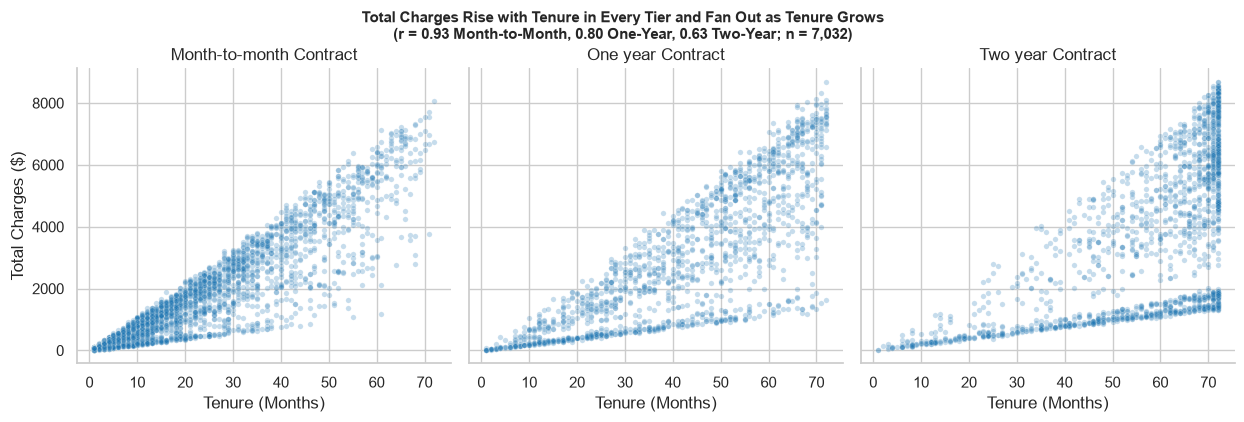

In [5]:
print("=== PART 3: FACETED RELATIONSHIP CHART (QUESTION 5) ===")

# Prediction (Q5): TotalCharges will rise with tenure in all three panels, widening into a fan as monthly plan rates diverge, with Two-year contracts clustering heavily near 72 months.

contract_order = ['Month-to-month', 'One year', 'Two year']
valid_telco = telco.dropna(subset=['TotalCharges'])

tier_r = valid_telco.groupby('Contract')[['tenure', 'TotalCharges']].apply(
    lambda d: d['tenure'].corr(d['TotalCharges'])
)
print("Within-Tier Correlations (tenure vs. TotalCharges):")
print(tier_r.round(2))

# Test the 72-month clustering prediction explicitly
tenure_cluster = valid_telco.groupby('Contract')['tenure'].agg(
    median_tenure='median',
    pct_at_72_mos=lambda s: (s == 72).mean() * 100
).round(1)
print("\nTenure Clustering Check by Contract:")
print(tenure_cluster)

r_mtm = tier_r['Month-to-month']
r_1yr = tier_r['One year']
r_2yr = tier_r['Two year']

g = sns.relplot(
    data=valid_telco,
    x='tenure', y='TotalCharges',
    col='Contract', col_order=contract_order,
    kind='scatter', color='#1f77b4', alpha=0.25, s=15,
    height=4, aspect=1.05
)

g.set_axis_labels('Tenure (Months)', 'Total Charges ($)')
g.set_titles('{col_name} Contract')
g.figure.suptitle(
    f'Total Charges Rise with Tenure in Every Tier and Fan Out as Tenure Grows\n(r = {r_mtm:.2f} Month-to-Month, {r_1yr:.2f} One-Year, {r_2yr:.2f} Two-Year; n = {len(valid_telco):,})',
    y=1.05, fontsize=11, fontweight='bold'
)
plt.show()

# Result check (Q5): Both predictions held — within-tier correlations are r = 0.93 (Month-to-month), r = 0.80 (One year), and r = 0.63 (Two year) with a widening vertical fan, and Two-year contracts cluster strongly at the upper cap (median 64.0 months, with 20.4% at exactly 72 months vs. <2% in other tiers).


In [6]:
print("=== PART 4: CONTRACT SHARE VERIFICATION (QUESTION 2) ===")
contract_shares = telco['Contract'].value_counts(normalize=True).mul(100).round(1)
print(contract_shares)


=== PART 4: CONTRACT SHARE VERIFICATION (QUESTION 2) ===
Contract
Month-to-month    55.0
Two year          24.1
One year          20.9
Name: proportion, dtype: float64


### Part 4: Defending a Sorted Bar Chart Over a Pie Chart (Question 2)

* **Decision:** Even though `Contract` has only three categories (`55.0%` Month-to-month, `24.1%` Two year, `20.9%` One year), a **sorted vertical bar chart with percentage labels** is safer and clearer than a pie chart.
* **Defense to a Stakeholder:** Human eyes compare lengths along a shared horizontal baseline far more accurately than angles or wedge areas, making the `3.2` percentage-point difference between Two-year (`24.1%`) and One-year (`20.9%`) contracts easier to compare without mental rotation. Using a sorted bar chart also keeps category labels horizontal and readable while reserving a single accent colour for the dominant Month-to-month segment (`55.0%`).
